In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm
from linearmodels.iv import IV2SLS
from linearmodels.panel import PanelOLS
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

In [2]:
# Ignore innocuous warnings below caused by missing observations
import warnings
from linearmodels.shared.exceptions import MissingValueWarning
warnings.filterwarnings('ignore', category=MissingValueWarning)

## Load data and residualize shock

In [3]:
# Load Bilal & Känzig (2026) data
df = pd.read_csv('data/bilal_kaenzig_2026.csv', index_col='year')
df = df.loc[1960:]

df = df.rename(columns={
    'lnrgdppc_world_pwt': 'l_gdp',
    'gtmp_bkly_aw_dtfe2s': 'temp_anom',
    'gtmp_bkly_aw': 'temp'
})

In [4]:
controls = ['l_gdp', 'temp_anom', 'lnpoil_wti', 'treasury1y', 'recessiondates']
nlag = 2
df = df.assign(**{
    f'{var}_lag{l}': df[var].shift(l)
    for var in controls for l in range(1, nlag + 1)
})
lag_cols = [f'{var}_lag{l}' for var in controls for l in range(1, nlag + 1)]
control_cols = ['recessiondates'] + lag_cols

df['temp_anom_resid'] = sm.OLS(df['temp_anom'], sm.add_constant(df[control_cols]),
                               missing='drop').fit().resid

## Forecast error variance decomposition

In [5]:
max_horizon = 10

# Leads of residualized shock
for l in range(max_horizon + 1):
    df[f'temp_anom_resid_lead{l}'] = df['temp_anom_resid'].shift(-l)

# Estimate FEVD
fevd = np.empty(max_horizon + 1)
for h in range(max_horizon + 1):
    y = df['l_gdp'].shift(-h)
    reg1 = sm.OLS(y, sm.add_constant(df[control_cols]), missing='drop').fit()
    cols = [f'temp_anom_resid_lead{l}' for l in range(h + 1)]
    reg2 = sm.OLS(reg1.resid,
                  sm.add_constant(df.loc[reg1.resid.index, cols]),
                  missing='drop').fit()
    fevd[h] = reg2.rsquared

h_grid = np.arange(max_horizon + 1)
print(pd.Series(fevd, index=pd.Index(h_grid, name='h'), name='FEVD').to_frame())

        FEVD
h           
0   0.017150
1   0.023892
2   0.061400
3   0.113741
4   0.160317
5   0.226175
6   0.302844
7   0.324311
8   0.273270
9   0.267634
10  0.266006


## LP-IV

In [6]:
def local_projection_iv(df, outcome, norm_var, proxy, controls, max_horz):
    """LP-IV: instrument norm_var with proxy."""
    irf = np.empty(max_horz + 1)
    se  = np.empty(max_horz + 1)
    for h in range(max_horz + 1):
        y = df[outcome].shift(-h)
        exog = sm.add_constant(df[controls])
        reg = IV2SLS(dependent=y, exog=exog,
                     endog=df[[norm_var]], instruments=df[[proxy]]
                     ).fit(cov_type='robust')
        irf[h] = reg.params[norm_var]
        se[h]  = reg.std_errors[norm_var]
    return irf, se

In [7]:
# First-stage regression
X = sm.add_constant(df[['temp_anom'] + lag_cols])
res = sm.OLS(df['temp'], X, missing='drop').fit(cov_type='HC1')
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                   temp   R-squared:                       0.962
Model:                            OLS   Adj. R-squared:                  0.953
Method:                 Least Squares   F-statistic:                     177.6
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           8.09e-34
Time:                        14:02:23   Log-Likelihood:                 78.687
No. Observations:                  58   AIC:                            -133.4
Df Residuals:                      46   BIC:                            -108.6
Df Model:                          11                                         
Covariance Type:                  HC1                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  13.9362    

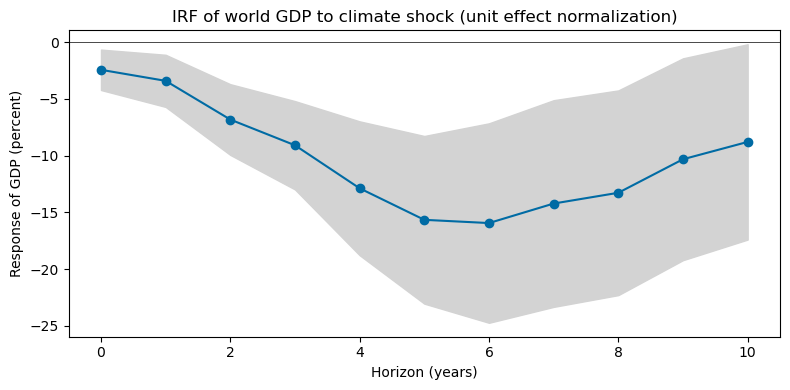

In [8]:
# Estimate unit-effect-normalized IRF
irf, se = local_projection_iv(df, 'l_gdp', 'temp', 'temp_anom',
                              lag_cols, max_horizon)
# We really should also be controlling for lags of 'temp'
# - feel free to experiment with this on your own

# Plot IRF and confidence band
signif = 0.32
cv = norm.ppf(1 - signif / 2)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_grid, irf, marker='o')
ax.fill_between(h_grid, irf - cv*se, irf + cv*se, color='lightgrey')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Horizon (years)')
ax.set_ylabel('Response of GDP (percent)')
ax.set_title(r'IRF of world GDP to climate shock (unit effect normalization)')
plt.tight_layout()
fig.savefig('output/bk_irf_unitnorm.eps')
plt.show()

## Panel LP

In [9]:
# Load country panel data
df_panel = pd.read_csv('data/bilal_kaenzig2026_panel.csv')
df_panel = df_panel[df_panel['year'] >= 1960].copy()
df_panel = df_panel.set_index(['country_code', 'year']).sort_index()

# Avg temperature by country
df_panel['avgtemp'] = df_panel.groupby('country_code')['lctmp_bkly_pw'].transform('mean')

# Own lags of outcome (within country)
for l in range(1, nlag + 1):
    df_panel[f'lnrgdppc_pwt_lag{l}'] = (
        df_panel.groupby(level='country_code')['lnrgdppc_pwt'].shift(l)
    )

# Merge in aggregate shock + controls
df_panel = df_panel.join(df[['temp_anom'] + control_cols], on='year')

In [10]:
# Interaction term
avgtemp_global = df_panel.groupby(level='country_code')['avgtemp'].first().mean()
df_panel['avgtemp_d'] = df_panel['avgtemp'] - avgtemp_global # de-mean
df_panel['temp_anom_x_avgtemp'] = df_panel['temp_anom'] * df_panel['avgtemp_d']

# Panel LP with unit FE and time-clustered SE
own_lag_cols = [f'lnrgdppc_pwt_lag{l}' for l in range(1, nlag + 1)]
panel_regs = own_lag_cols + ['temp_anom', 'temp_anom_x_avgtemp'] + control_cols

irf_panel = np.empty(max_horizon + 1)
se_panel  = np.empty(max_horizon + 1)
inter_panel = np.empty(max_horizon + 1)
inter_se_panel = np.empty(max_horizon + 1)
for h in range(max_horizon + 1):
    y = df_panel.groupby(level='country_code')['lnrgdppc_pwt'].shift(-h)
    reg = PanelOLS(y, df_panel[panel_regs], entity_effects=True
                   ).fit(cov_type='clustered', cluster_time=True)
    irf_panel[h] = reg.params['temp_anom']
    se_panel[h]  = reg.std_errors['temp_anom']
    inter_panel[h] = reg.params['temp_anom_x_avgtemp']
    inter_se_panel[h] = reg.std_errors['temp_anom_x_avgtemp']

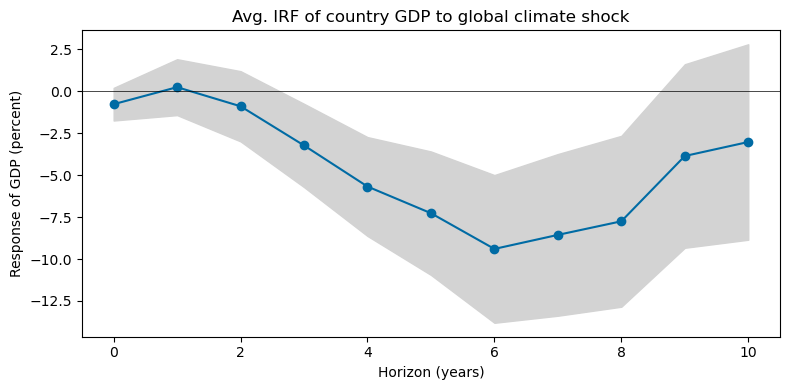

     beta  beta_se    phi  phi_se
h                                
0  -0.768    0.979 -0.243   0.160
1   0.247    1.677 -0.406   0.257
2  -0.892    2.106 -0.538   0.327
3  -3.228    2.498 -0.570   0.349
4  -5.678    2.965 -0.624   0.389
5  -7.268    3.702 -0.720   0.417
6  -9.399    4.429 -0.801   0.412
7  -8.561    4.848 -0.722   0.423
8  -7.750    5.124 -0.749   0.411
9  -3.858    5.503 -0.822   0.359
10 -3.023    5.861 -0.799   0.348


In [11]:
# Plot average panel IRF and confidence band
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_grid, irf_panel, marker='o')
ax.fill_between(h_grid, irf_panel - cv*se_panel, irf_panel + cv*se_panel, color='lightgrey')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Horizon (years)')
ax.set_ylabel('Response of GDP (percent)')
ax.set_title('Avg. IRF of country GDP to global climate shock')
plt.tight_layout()
fig.savefig('output/bk_irf_panel.eps')
plt.show()

# Avg impulse response and interaction coefficient by horizon
print(pd.DataFrame({'beta': irf_panel, 'beta_se': se_panel,
                    'phi': inter_panel, 'phi_se': inter_se_panel},
                   index=pd.Index(h_grid, name='h')).round(3))